# Grammar Scoring from Spoken Audio

**Approach**
1. Each clip is passed through several pretrained speech models (WavLM, HuBERT, wav2vec2, Whisper encoders). The mean and std of every layer's hidden states over time describe the clip.
2. Each model ("view") becomes a similarity matrix (kernel) between all clips. No labels are used here.
3. Kernel ridge regression (KRR) is trained on each view and on the average of all views. Its regularisation is chosen inside every training fold by exact leave-one-out error.
4. A small non-negative linear stacker combines the models (a handful of weights, fitted on out-of-fold predictions only).
5. Honest score = repeated 5-fold cross-validation (CV). Training RMSE is printed as well but is only a sanity number.

Features are cached in `./working/cache`; only missing views are extracted. Caches from earlier runs with the same folder are reused automatically.

In [1]:
!pip install -q openai-whisper kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 29.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Setup and configuration

In [2]:
import gc, math, time, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# ---------------- configuration ----------------
DATA_ROOT = None                 # folder that contains train.csv (None = download from Kaggle)
SR = 16000                       # sample rate expected by all models
MAX_SEC = 60                     # clips are cut to this length
CHUNK = 30 * SR                  # Whisper encoder window (30 s)

# name -> (model family, model id). Remove a line to skip that view.
VIEW_SPECS = {
    "WavLM-base":           ("hf",      "microsoft/wavlm-base-plus"),
    "WavLM-large":          ("hf",      "microsoft/wavlm-large"),
    "HuBERT-large":         ("hf",      "facebook/hubert-large-ll60k"),
    "Wav2Vec2-large-960h":  ("hf",      "facebook/wav2vec2-large-960h-lv60-self"),
    "Whisper-small enc":    ("whisper", "small"),
    "Whisper-medium enc":   ("whisper", "medium"),
    "Whisper-large-v3 enc": ("whisper", "large-v3"),
}

WORK = Path("./working"); CACHE = WORK / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

def rmse(y_true, y_pred):
    # root mean squared error
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def free_gpu():
    # release memory after a model is no longer needed
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

Device: cuda


## 2. Load data

In [3]:
# locate the competition files (Kaggle download, or DATA_ROOT / /kaggle/input as fallback)
if DATA_ROOT is None:
    try:
        import kagglehub
        DATA_ROOT = kagglehub.competition_download("shl-hiring-assessment-2026")
    except Exception as e:
        print("kagglehub failed:", repr(e)[:120])
        DATA_ROOT = "/kaggle/input"
train_csv = next(Path(DATA_ROOT).rglob("train.csv"))
DATA_DIR = train_csv.parent

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

# map every file name to its wav path
train_lookup = {p.name: p for p in (DATA_DIR / "train").rglob("*.wav")}
test_lookup = {p.name: p for p in (DATA_DIR / "test").rglob("*.wav")}
train_df["audio_path"] = train_df["filename"].map(train_lookup)
test_df["audio_path"] = test_df["filename"].map(test_lookup)
assert train_df["audio_path"].notna().all() and test_df["audio_path"].notna().all()

# train and test are stacked in one table so each feature extractor runs once (rows 0..N_TRAIN-1 are train)
all_df = pd.concat([train_df, test_df], ignore_index=True)
N_TRAIN, N_ALL = len(train_df), len(all_df)
y = train_df["label"].astype(float).values
Y_MIN, Y_MAX = y.min(), y.max()          # predictions are clipped to the observed label range
print("Train:", N_TRAIN, "| Test:", len(test_df), "| predict-mean RMSE: %.3f" % y.std())

def load_audio(p):
    # read as 16 kHz mono, cut to MAX_SEC, pad very short clips to 1 s
    a, _ = librosa.load(str(p), sr=SR, mono=True)
    a = a[: SR * MAX_SEC]
    if len(a) < SR:
        a = np.pad(a, (0, SR - len(a)))
    return a.astype(np.float32)

Train: 769 | Test: 216 | predict-mean RMSE: 1.238


## 3. Audio embeddings (one view per speech model)
For every clip and every layer we store the mean and std of the hidden states over time. Arrays have shape `(clips, layers, dim)`.

In [4]:
from transformers import AutoFeatureExtractor, AutoModel
import whisper

def pool_hidden(hs):
    # hs: tuple of (1, time, dim) tensors, one per layer -> per-layer mean and std over time
    mean = torch.stack([h[0].float().mean(0) for h in hs]).cpu().numpy()
    std = torch.stack([h[0].float().std(0) for h in hs]).cpu().numpy()
    return mean, std

@torch.no_grad()
def hf_pooled(model, feat_ext, a):
    # one clip through a Hugging Face speech model (half precision on GPU)
    x = feat_ext(a, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
    with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
        hs = model(x, output_hidden_states=True).hidden_states
    m, s = pool_hidden(hs)
    if not (np.isfinite(m).all() and np.isfinite(s).all()):      # repeat in full precision if fp16 overflowed
        hs = model(x, output_hidden_states=True).hidden_states
        m, s = pool_hidden(hs)
    return m, s

def run_hf(model_id):
    # embeddings of all clips from one Hugging Face model
    fe = AutoFeatureExtractor.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id).to(DEVICE).eval()
    ms, ss = [], []
    for p in tqdm(all_df["audio_path"], desc=model_id.split("/")[-1]):
        m, s = hf_pooled(model, fe, load_audio(p)); ms.append(m); ss.append(s)
    del model, fe; free_gpu()
    return np.stack(ms).astype(np.float32), np.stack(ss).astype(np.float32)

@torch.no_grad()
def whisper_pooled(enc, store, a, n_mels):
    # Whisper encoder works on 30 s windows; running sums give mean/std over real (unpadded) frames only
    L = len(enc.blocks); D = enc.ln_post.weight.shape[0]
    s1 = torch.zeros(L, D, device=DEVICE); s2 = torch.zeros(L, D, device=DEVICE); n = 0
    for start in range(0, len(a), CHUNK):
        chunk = a[start:start + CHUNK]
        if start > 0 and len(chunk) < 2 * SR:                     # skip a tiny last piece
            break
        mel = whisper.log_mel_spectrogram(whisper.pad_or_trim(chunk), n_mels=n_mels).to(DEVICE)[None]
        valid = min(1500, math.ceil(len(chunk) / 320))            # 1 encoder frame = 320 samples
        store.clear()
        with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
            enc(mel)
        H = torch.stack([o[0, :valid].float() for o in store])   # (layers, valid frames, dim)
        s1 += H.sum(1); s2 += (H ** 2).sum(1); n += valid
        del H
    mean = s1 / n
    return mean.cpu().numpy(), (s2 / n - mean ** 2).clamp_min(0).sqrt().cpu().numpy()

def run_whisper(size):
    # embeddings of all clips from one Whisper encoder (decoder is dropped to save memory)
    wm = whisper.load_model(size, device=DEVICE)
    enc = wm.encoder.eval(); n_mels = wm.dims.n_mels
    wm.decoder = None; free_gpu()
    store = []
    hooks = [b.register_forward_hook(lambda m_, i_, o_: store.append(o_)) for b in enc.blocks]   # grab every block output
    ms, ss = [], []
    for p in tqdm(all_df["audio_path"], desc=f"Whisper-{size} encoder"):
        m, s = whisper_pooled(enc, store, load_audio(p), n_mels); ms.append(m); ss.append(s)
    for h in hooks: h.remove()
    del wm, enc, store; free_gpu()
    return np.stack(ms).astype(np.float32), np.stack(ss).astype(np.float32)

In [5]:
# ---- collect cached views (older cache files of the same folder are read if present) ----
def read_old_caches():
    found = {}
    f = CACHE / "audio_small_wavlm-base-plus.pkl"
    if f.exists():
        A = pd.read_pickle(f)
        found["WavLM-base"] = (A["wavlm_mean"], A["wavlm_std"])
        found["Whisper-small enc"] = (A["whis_mean"], A["whis_std"])
    f = CACHE / "extra_wavlm-large_medium.pkl"
    if f.exists():
        found.update(pd.read_pickle(f))
    return found

VIEW_CACHE = CACHE / "audio_views.pkl"            # views computed by this notebook
RAW = read_old_caches()
if VIEW_CACHE.exists():
    RAW.update(pd.read_pickle(VIEW_CACHE))
RAW = {k: v for k, v in RAW.items() if k in VIEW_SPECS}

# ---- extract whatever is still missing; a view that fails to load is skipped ----
NEW = {k: v for k, v in (pd.read_pickle(VIEW_CACHE).items() if VIEW_CACHE.exists() else [])}
for name, (family, model_id) in VIEW_SPECS.items():
    if name in RAW:
        continue
    try:
        RAW[name] = run_hf(model_id) if family == "hf" else run_whisper(model_id)
        NEW[name] = RAW[name]
        pd.to_pickle(NEW, VIEW_CACHE)
    except Exception as e:
        print(f"View '{name}' skipped:", repr(e)[:200]); free_gpu()
print({k: v[0].shape for k, v in RAW.items()})

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

...

100%|██████████████████████████████████████| 1.42G/1.42G [00:09<00:00, 159MiB/s]


Whisper-medium encoder:   0%|          | 0/985 [00:00<?, ?it/s]

100%|██████████████████████████████████████| 2.88G/2.88G [00:16<00:00, 192MiB/s]


Whisper-large-v3 encoder:   0%|          | 0/985 [00:00<?, ?it/s]

{'WavLM-base': (985, 13, 768), 'WavLM-large': (985, 25, 1024), 'HuBERT-large': (985, 25, 1024), 'Wav2Vec2-large-960h': (985, 25, 1024), 'Whisper-small enc': (985, 12, 768), 'Whisper-medium enc': (985, 24, 1024), 'Whisper-large-v3 enc': (985, 32, 1280)}


## 4. One kernel per view
Each layer's `[mean, std]` features are z-scored over all clips (no labels involved) and turned into a clips x clips linear kernel. The kernels of all layers are averaged, so no single layer has to be picked. The raw arrays are freed straight afterwards.

In [6]:
def view_kernel(mean_emb, std_emb):
    # average over layers of the linear kernel of z-scored [mean, std] features
    n, L = mean_emb.shape[0], mean_emb.shape[1]
    K = np.zeros((n, n), dtype=np.float64)
    for l in range(L):
        Z = np.concatenate([mean_emb[:, l], std_emb[:, l]], axis=1).astype(np.float32)
        Z = np.nan_to_num(Z)
        Z = (Z - Z.mean(0)) / (Z.std(0) + 1e-6)          # per-feature standardisation
        K += (Z @ Z.T) / Z.shape[1]                       # scaled so the diagonal is about 1
    return (K / L).astype(np.float32)

K_view = {}
for name in list(RAW):
    mn, sd = RAW.pop(name)                                # pop frees the raw arrays after use
    K_view[name] = view_kernel(mn, sd)
    del mn, sd; gc.collect()
print("Views used:", list(K_view))

Views used: ['WavLM-base', 'WavLM-large', 'HuBERT-large', 'Wav2Vec2-large-960h', 'Whisper-small enc', 'Whisper-medium enc', 'Whisper-large-v3 enc']


## 5. Cross-validation tools and kernel ridge
* `cv_oof` returns out-of-fold predictions (5-fold, stratified on the score, repeated 3 times and averaged).
* `krr` is kernel ridge with an intercept. The regularisation strength is picked on the training part of each fold by exact leave-one-out error, so it never sees the validation rows.

In [7]:
BINS = np.digitize(y, [0.5, 2.25, 3.25, 4.25, 4.75])      # score groups used to stratify the folds

def cv_oof(fn, n_repeats=3, n_splits=5):
    # fn(train_idx, eval_idx) -> predictions for eval_idx; returns one out-of-fold prediction per training clip
    oof = np.zeros((n_repeats, N_TRAIN))
    for r in range(n_repeats):
        skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED + r)
        for tr, va in skf.split(np.zeros(N_TRAIN), BINS):
            oof[r, va] = fn(tr, va)
    return np.clip(oof.mean(0), Y_MIN, Y_MAX)

ALPHAS = np.logspace(-3, 3, 25)                            # candidate ridge strengths

def krr(K, tr, te):
    # kernel ridge: centre the kernel (this gives the intercept), eigendecompose once, try every alpha cheaply
    Ktr = K[np.ix_(tr, tr)].astype(np.float64)
    Kte = K[np.ix_(te, tr)].astype(np.float64)
    cm = Ktr.mean(0); tm = cm.mean()
    Kc = Ktr - cm[None, :] - cm[:, None] + tm
    Kte_c = Kte - Kte.mean(1, keepdims=True) - cm[None, :] + tm
    ym = y[tr].mean(); yc = y[tr] - ym
    s, U = np.linalg.eigh(Kc); s = np.clip(s, 0, None)
    Uty = U.T @ yc; U2 = U ** 2
    best_a, best_e = ALPHAS[0], np.inf
    for a in ALPHAS:                                       # exact leave-one-out error for each alpha
        shrink = s / (s + a)
        loo = (yc - U @ (shrink * Uty)) / np.maximum(1 - 1 / len(tr) - U2 @ shrink, 1e-6)
        e = np.mean(loo ** 2)
        if e < best_e:
            best_a, best_e = a, e
    return Kte_c @ (U @ (Uty / (s + best_a))) + ym         # predictions with the chosen alpha

krr_fn = lambda K: (lambda tr, te: krr(K, tr, te))

def rbf_from_linear(K, gamma):
    # Gaussian kernel built from the distances implied by a linear kernel; width scaled by the median distance
    d = np.diag(K)
    D2 = np.maximum(d[:, None] + d[None, :] - 2 * K, 0)
    med = np.median(D2[np.triu_indices_from(D2, 1)])
    return np.exp(-gamma * D2 / med).astype(np.float32)

## 6. Base models
* One RBF kernel ridge per view.
* One linear and one RBF kernel ridge on the **equal-weight average** of all view kernels (no weights tuned).
* The RBF width is chosen from only three values by CV.

In [8]:
# average of all view kernels (equal weights)
K_avg = np.mean(list(K_view.values()), axis=0)

# pick the RBF width (3 candidates) using the averaged kernel
GAMMAS = (0.5, 1.0, 2.0)
BEST_GAMMA = min(GAMMAS, key=lambda g: rmse(y, cv_oof(krr_fn(rbf_from_linear(K_avg, g)), n_repeats=1)))
print("RBF width multiplier:", BEST_GAMMA)

K_rbf_avg = rbf_from_linear(K_avg, BEST_GAMMA)

# model table: name -> function(train_idx, eval_idx) -> predictions
models = {f"RBF {n}": krr_fn(rbf_from_linear(K, BEST_GAMMA)) for n, K in K_view.items()}
models["RBF all views"] = krr_fn(K_rbf_avg)
models["Linear all views"] = krr_fn(K_avg)

# out-of-fold predictions of every model
oof = {}
for name, fn in models.items():
    t0 = time.time()
    oof[name] = cv_oof(fn)
    print(f"{name:28s} CV RMSE {rmse(y, oof[name]):.4f} | Pearson {pearsonr(y, oof[name])[0]:.3f} | {time.time()-t0:.0f}s")
names = list(oof)
oof_mat = np.column_stack([oof[n] for n in names])

RBF width multiplier: 0.5
RBF WavLM-base               CV RMSE 0.5104 | Pearson 0.912 | 1s
RBF WavLM-large              CV RMSE 0.4895 | Pearson 0.919 | 1s
RBF HuBERT-large             CV RMSE 0.5113 | Pearson 0.911 | 1s
RBF Wav2Vec2-large-960h      CV RMSE 0.5072 | Pearson 0.912 | 1s
RBF Whisper-small enc        CV RMSE 0.4953 | Pearson 0.917 | 1s
RBF Whisper-medium enc       CV RMSE 0.4828 | Pearson 0.922 | 1s
RBF Whisper-large-v3 enc     CV RMSE 0.4957 | Pearson 0.917 | 1s
RBF all views                CV RMSE 0.4768 | Pearson 0.923 | 1s
Linear all views             CV RMSE 0.4847 | Pearson 0.921 | 1s


## 7. Stacking
A non-negative linear regression on the out-of-fold predictions decides how much each model counts. It has one weight per model plus an intercept. Its own score is estimated by a second CV on the out-of-fold matrix.

In [9]:
# fit the stacker on out-of-fold predictions only
stacker = LinearRegression(positive=True).fit(oof_mat, y)
print("Stack weights:", {n: round(float(w), 3) for n, w in zip(names, stacker.coef_) if w > 0.001},
      "| intercept %.3f" % stacker.intercept_)

# honest estimate of the stacked model: CV over the out-of-fold matrix, repeated 3 times
stack_runs = []
for r in range(3):
    p = np.zeros(N_TRAIN)
    for tr, va in KFold(5, shuffle=True, random_state=SEED + r).split(oof_mat):
        p[va] = LinearRegression(positive=True).fit(oof_mat[tr], y[tr]).predict(oof_mat[va])
    stack_runs.append(np.clip(p, Y_MIN, Y_MAX))
stack_cv = stack_runs[0]
cv_rmse_stack = float(np.mean([rmse(y, p) for p in stack_runs]))
cv_pearson = float(np.mean([pearsonr(y, p)[0] for p in stack_runs]))
cv_r2 = float(np.mean([r2_score(y, p) for p in stack_runs]))
cv_mae = float(np.mean([mean_absolute_error(y, p) for p in stack_runs]))

print(f"\nStacked CV RMSE   : {cv_rmse_stack:.4f}")
print(f"Stacked CV MAE    : {cv_mae:.4f}")
print(f"Stacked CV R2     : {cv_r2:.4f}")
print(f"Stacked CV Pearson: {cv_pearson:.4f}")
print(f"Predict-mean RMSE : {y.std():.4f}")

Stack weights: {'RBF WavLM-large': 0.266, 'RBF HuBERT-large': 0.053, 'RBF Wav2Vec2-large-960h': 0.025, 'RBF Whisper-medium enc': 0.474, 'RBF all views': 0.137, 'Linear all views': 0.091} | intercept -0.145

Stacked CV RMSE   : 0.4736
Stacked CV MAE    : 0.3473
Stacked CV R2     : 0.8537
Stacked CV Pearson: 0.9241
Predict-mean RMSE : 1.2382


## 8. Final fit on all training clips and test predictions
Every base model is refitted on all training clips (alpha again chosen by leave-one-out), the stacker combines them. The in-sample training RMSE is a sanity number only; the CV RMSE above is the generalisation estimate.

In [10]:
tr_idx, all_idx = np.arange(N_TRAIN), np.arange(N_ALL)

# predictions of every base model for train and test rows
P = np.column_stack([np.clip(fn(tr_idx, all_idx), Y_MIN, Y_MAX) for fn in models.values()])
train_pred = np.clip(stacker.predict(P[:N_TRAIN]), Y_MIN, Y_MAX)
test_pred = np.clip(stacker.predict(P[N_TRAIN:]), Y_MIN, Y_MAX)

TRAIN_RMSE = rmse(y, train_pred)
print("=" * 60)
print(f"TRAINING RMSE (in-sample)               : {TRAIN_RMSE:.4f}")
print(f"CROSS-VALIDATED RMSE (honest estimate)  : {cv_rmse_stack:.4f}")
print("=" * 60)

TRAINING RMSE (in-sample)               : 0.0417
CROSS-VALIDATED RMSE (honest estimate)  : 0.4736


## 9. Submission

In [11]:
submission = pd.DataFrame({"filename": test_df["filename"].values, "label": test_pred})
assert len(submission) == len(test_df) and submission["label"].notna().all()
if list(sample_sub.columns) != list(submission.columns):
    print("WARNING: sample_submission columns are", list(sample_sub.columns), "- rename before submitting")
print("Prediction range: %.2f - %.2f | mean %.2f" % (submission["label"].min(), submission["label"].max(), submission["label"].mean()))
submission.to_csv(WORK / "submission.csv", index=False)
print("Saved:", WORK / "submission.csv")
submission.head()

Prediction range: 1.51 - 5.00 | mean 3.27
Saved: working/submission.csv


,filename,label
0,audio_128.wav,2.800002
1,audio_156.wav,4.423838
2,audio_19.wav,4.647064
3,audio_108.wav,2.223671
4,audio_206.wav,2.154161


## 10. Diagnostics

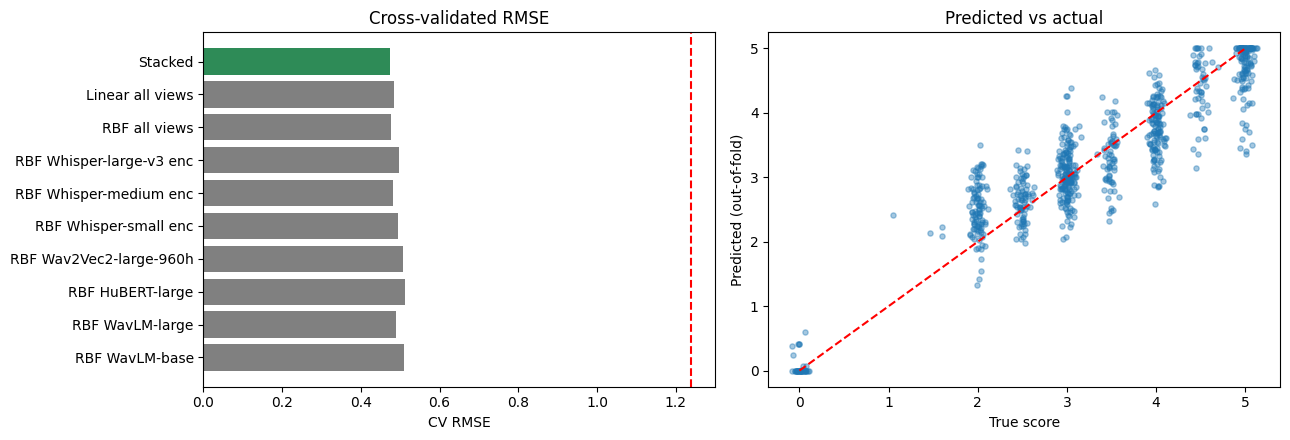

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# CV RMSE of every base model and of the stack
res = {n: rmse(y, oof[n]) for n in names}; res["Stacked"] = cv_rmse_stack
ax[0].barh(list(res), list(res.values()), color=["gray"] * len(names) + ["seagreen"])
ax[0].axvline(y.std(), color="red", ls="--")
ax[0].set_xlabel("CV RMSE"); ax[0].set_title("Cross-validated RMSE")

# out-of-fold prediction against the true score
jit = np.random.normal(0, 0.05, len(y))
ax[1].scatter(y + jit, stack_cv, alpha=0.4, s=14); ax[1].plot([Y_MIN, Y_MAX], [Y_MIN, Y_MAX], "r--")
ax[1].set_xlabel("True score"); ax[1].set_ylabel("Predicted (out-of-fold)"); ax[1].set_title("Predicted vs actual")
plt.tight_layout(); plt.show()